# 4 · The turbofan

Lesson: [04](../docs/lessons/04-turbofan.md) · Theory: [turbofan model](../docs/turbofan_model.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from propulsion import plotting as P
from propulsion.flight import FlightCondition
from propulsion.units import FT, tsfc_to_lb_per_lbf_h

P.use_style()
np.set_printoptions(precision=4, suppress=True)
FL350 = FlightCondition.at_altitude(35000 * FT, 0.78, geopotential=True)
SLS = FlightCondition.sea_level_static()
from propulsion.component_models import Components
from propulsion.gas import AIR
from propulsion.turbofan_model import (turbofan, optimum_bypass_ratio,
                                       optimum_fan_pressure_ratio)

## The worked example of Lesson 4

In [2]:
p = turbofan(FL350, alpha=5.5, pi_f=1.7, pi_c=32.0, Tt4=1450.0, pi_cL=1.6,
             components=Components.modern())
e = p.extras
print(f"F/m0 = {float(p.specific_thrust):.1f} N s/kg (core {float(e['specific_thrust_core']):.1f}, "
      f"fan {float(e['specific_thrust_fan']):.1f})")
print(f"TSFC = {float(p.tsfc)*1e6:.2f} mg/(N s);  V9 = {float(p.V9):.1f}, V19 = {float(e['V19']):.1f} m/s")
print(f"eta_T = {float(p.eta_thermal):.3f}, eta_P = {float(p.eta_propulsive):.3f}")

F/m0 = 193.8 N s/kg (core 78.8, fan 115.0)
TSFC = 18.99 mg/(N s);  V9 = 726.3, V19 = 367.1 m/s
eta_T = 0.456, eta_P = 0.624


## Bypass-ratio sweep (fixed core) and the ideal optima

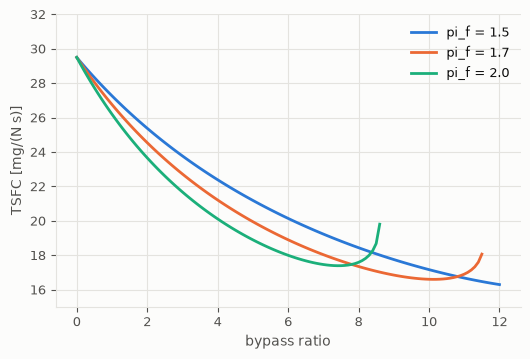

ideal alpha* = 15.248: V9 - V0 = 67.52, (V19 - V0)/2 = 67.52 m/s
ideal pi_f* (alpha = 10) = 2.085: V9 = 410.54, V19 = 410.54


In [3]:
alpha = np.linspace(0.0, 12.0, 121)
fig, ax = plt.subplots(figsize=(6, 3.8))
for pi_f in (1.5, 1.7, 2.0):
    q = turbofan(FL350, alpha, pi_f, 32.0, 1500.0, pi_cL=1.6, components=Components.modern())
    ax.plot(alpha, q.tsfc * 1e6, label=f"pi_f = {pi_f}")
ax.set_xlabel("bypass ratio"); ax.set_ylabel("TSFC [mg/(N s)]"); ax.set_ylim(15, 32); ax.legend()
plt.show()
ideal = dict(components=Components(), hot=AIR, include_fuel_mass=False)
a_star = float(optimum_bypass_ratio(FL350, 1.7, 30.0, 1600.0))
q = turbofan(FL350, a_star, 1.7, 30.0, 1600.0, **ideal)
print(f"ideal alpha* = {a_star:.3f}: V9 - V0 = {float(q.V9 - q.V0):.2f}, "
      f"(V19 - V0)/2 = {float(q.extras['V19'] - q.V0)/2:.2f} m/s")
pf_star = float(optimum_fan_pressure_ratio(FL350, 10.0, 30.0, 1600.0))
q = turbofan(FL350, 10.0, pf_star, 30.0, 1600.0, **ideal)
print(f"ideal pi_f* (alpha = 10) = {pf_star:.3f}: V9 = {float(q.V9):.2f}, V19 = {float(q.extras['V19']):.2f}")